In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerTuple

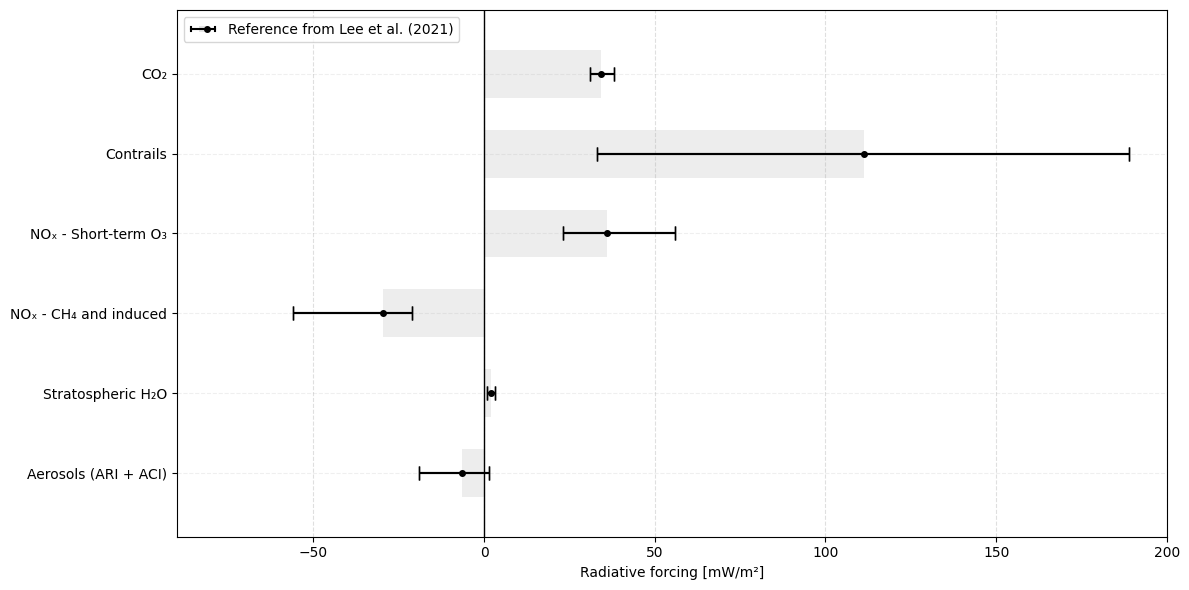

In [9]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase
from matplotlib.legend_handler import HandlerTuple

# --- Données de référence D. Lee (2021) ---
reference_data_rf = {
    "Aerosols (ARI + ACI)": {
        "val": -7.4 + 0.94,
        "min": -19 + 0.1,
        "max": -2.6 + 4
    },
    "Stratospheric H₂O": {
        "val": 2.0,
        "min": 0.8,
        "max": 3.2
    },
    "NOₓ - CH₄ and induced": {
        "val": -29.6,
        "min": -56,
        "max": -21.2
    },
    "NOₓ - Short-term O₃": {
        "val": 36,
        "min": 23,
        "max": 56
    },
    "Contrails": {
        "val": 111.4,
        "min": 33,
        "max": 189
    },
    "CO₂": {
        "val": 34.3,
        "min": 31,
        "max": 38
    }
}

species_list = list(reference_data_rf.keys())

# --- Autres données ---
data_teoh_contrails = {
    "Contrails": 62.1 * 54.28 / 56.2
}
data_perini_contrails = {
    "Contrails": 45.6 * 54.28 / 56.2
}
data_zhang_contrails = {
    "Contrails": 40.8 / 0.55
}
data_righi_aerosols = {
    "Aerosols (ARI + ACI)": -64 * 0.34 / 0.29
}
data_yoshioka_aerosols = {
    "Aerosols (ARI + ACI)": -24
}


# --- Gestionnaire personnalisé pour la légende Lee ---

class HandlerLee(HandlerBase):
    def create_artists(
        self, legend, orig_handle, xdescent, ydescent,
        width, height, fontsize, trans
    ):
        ymid = ydescent + height / 2

        # Zéro au centre du symbole
        xzero = xdescent + width * 0.35
        xmean = xdescent + width * 0.65

        # Surface grise entre zéro et la moyenne
        rect = Rectangle(
            (xzero, ydescent + height * 0.2),
            xmean - xzero,
            height * 0.6,
            facecolor="lightgrey",
            alpha=0.6,
            edgecolor="none",
            transform=trans
        )

        # Moustaches horizontales
        whisker = Line2D(
            [xdescent + width * 0.08, xdescent + width * 0.92],
            [ymid, ymid],
            color="black",
            linewidth=1.5,
            transform=trans
        )

        # Extrémités des moustaches
        cap_left = Line2D(
            [xdescent + width * 0.08] * 2,
            [ymid - height * 0.2, ymid + height * 0.2],
            color="black",
            linewidth=1.5,
            transform=trans
        )

        cap_right = Line2D(
            [xdescent + width * 0.92] * 2,
            [ymid - height * 0.2, ymid + height * 0.2],
            color="black",
            linewidth=1.5,
            transform=trans
        )

        # Point noir central
        point = Line2D(
            [xmean], [ymid],
            color="black",
            marker="o",
            markersize=4,
            linestyle="none",
            transform=trans
        )

        return [rect, whisker, cap_left, cap_right, point]



# --- Figure ---
fig, ax = plt.subplots(figsize=(12, 6))
y_pos = np.arange(len(species_list))

# --- Référence Lee : barres grises et incertitudes ---
ref_vals = []
ref_y_pos = []
ref_xerr_lower = []
ref_xerr_upper = []

for i, spe in enumerate(species_list):
    ref = reference_data_rf[spe]

    if all(k in ref for k in ("val", "min", "max")):
        val = ref["val"]
        xmin = ref["min"]
        xmax = ref["max"]

        ref_vals.append(val)
        ref_y_pos.append(y_pos[i])
        ref_xerr_lower.append(val - xmin)
        ref_xerr_upper.append(xmax - val)

        ax.barh(
            y_pos[i],
            val,
            color="lightgrey",
            alpha=0.4,
            height=0.6
        )

        ax.errorbar(
            val,
            y_pos[i],
            xerr=[[val - xmin], [xmax - val]],
            fmt="none",
            ecolor="black",
            capsize=5,
            elinewidth=1.5
        )

# --- Moyennes de Lee et al. ---
# Les points et moustaches sont tracés sur le graphique.
ax.errorbar(
    ref_vals,
    ref_y_pos,
    xerr=[ref_xerr_lower, ref_xerr_upper],
    fmt="o",
    color="black",
    markersize=4,
    capsize=5,
    elinewidth=1.5,
    linestyle="none",
    label="_nolegend_",
    zorder=5
)


# --- Mise en forme ---
ax.set_yticks(y_pos)
ax.set_yticklabels(species_list)

ax.axvline(0, color="black", linewidth=1, linestyle="-")
ax.set_xlabel("Radiative forcing [mW/m²]")

ax.set_xlim(-90,200)
ax.set_ylim(-0.8, len(species_list) - 0.2)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.grid(axis="y", linestyle="--", alpha=0.2)

# --- Légende personnalisée ---
lee_handle = (34.3, 31, 38)  # Moyenne et bornes d'exemple pour le symbole

handles, labels = ax.get_legend_handles_labels()

handles.insert(0, lee_handle)
labels.insert(0, "Reference from Lee et al. (2021)")

ax.legend(
    handles,
    labels,
    handler_map={tuple: HandlerLee()},
    loc="upper left"
)

plt.tight_layout()
plt.savefig("lee_settings.png")
plt.show()


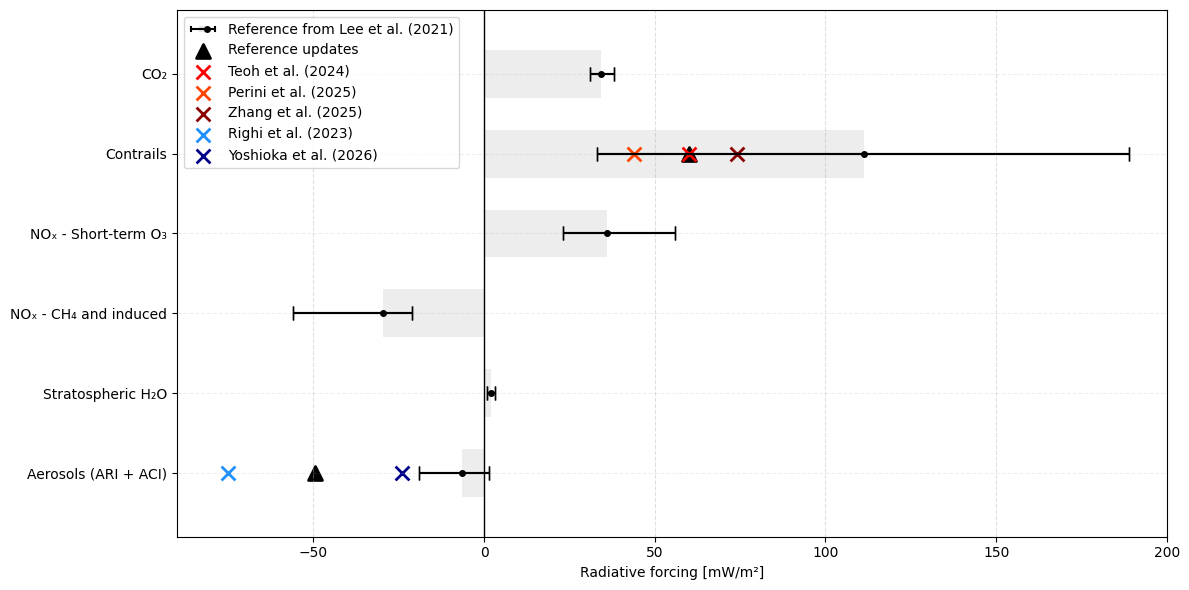

In [10]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase
from matplotlib.legend_handler import HandlerTuple

# --- Données de référence D. Lee (2021) ---
reference_data_rf = {
    "Aerosols (ARI + ACI)": {
        "val": -7.4 + 0.94,
        "min": -19 + 0.1,
        "max": -2.6 + 4
    },
    "Stratospheric H₂O": {
        "val": 2.0,
        "min": 0.8,
        "max": 3.2
    },
    "NOₓ - CH₄ and induced": {
        "val": -29.6,
        "min": -56,
        "max": -21.2
    },
    "NOₓ - Short-term O₃": {
        "val": 36,
        "min": 23,
        "max": 56
    },
    "Contrails": {
        "val": 111.4,
        "min": 33,
        "max": 189
    },
    "CO₂": {
        "val": 34.3,
        "min": 31,
        "max": 38
    }
}

species_list = list(reference_data_rf.keys())

# --- Autres données ---
data_teoh_contrails = {
    "Contrails": 62.1 * 54.28 / 56.2
}
data_perini_contrails = {
    "Contrails": 45.6 * 54.28 / 56.2
}
data_zhang_contrails = {
    "Contrails": 40.8 / 0.55
}
data_righi_aerosols = {
    "Aerosols (ARI + ACI)": -64 * 0.34 / 0.29
}
data_yoshioka_aerosols = {
    "Aerosols (ARI + ACI)": -24
}


# --- Gestionnaire personnalisé pour la légende Lee ---

class HandlerLee(HandlerBase):
    def create_artists(
        self, legend, orig_handle, xdescent, ydescent,
        width, height, fontsize, trans
    ):
        ymid = ydescent + height / 2

        # Zéro au centre du symbole
        xzero = xdescent + width * 0.35
        xmean = xdescent + width * 0.65

        # Surface grise entre zéro et la moyenne
        rect = Rectangle(
            (xzero, ydescent + height * 0.2),
            xmean - xzero,
            height * 0.6,
            facecolor="lightgrey",
            alpha=0.6,
            edgecolor="none",
            transform=trans
        )

        # Moustaches horizontales
        whisker = Line2D(
            [xdescent + width * 0.08, xdescent + width * 0.92],
            [ymid, ymid],
            color="black",
            linewidth=1.5,
            transform=trans
        )

        # Extrémités des moustaches
        cap_left = Line2D(
            [xdescent + width * 0.08] * 2,
            [ymid - height * 0.2, ymid + height * 0.2],
            color="black",
            linewidth=1.5,
            transform=trans
        )

        cap_right = Line2D(
            [xdescent + width * 0.92] * 2,
            [ymid - height * 0.2, ymid + height * 0.2],
            color="black",
            linewidth=1.5,
            transform=trans
        )

        # Point noir central
        point = Line2D(
            [xmean], [ymid],
            color="black",
            marker="o",
            markersize=4,
            linestyle="none",
            transform=trans
        )

        return [rect, whisker, cap_left, cap_right, point]



# --- Figure ---
fig, ax = plt.subplots(figsize=(12, 6))
y_pos = np.arange(len(species_list))

# --- Référence Lee : barres grises et incertitudes ---
ref_vals = []
ref_y_pos = []
ref_xerr_lower = []
ref_xerr_upper = []

for i, spe in enumerate(species_list):
    ref = reference_data_rf[spe]

    if all(k in ref for k in ("val", "min", "max")):
        val = ref["val"]
        xmin = ref["min"]
        xmax = ref["max"]

        ref_vals.append(val)
        ref_y_pos.append(y_pos[i])
        ref_xerr_lower.append(val - xmin)
        ref_xerr_upper.append(xmax - val)

        ax.barh(
            y_pos[i],
            val,
            color="lightgrey",
            alpha=0.4,
            height=0.6
        )

        ax.errorbar(
            val,
            y_pos[i],
            xerr=[[val - xmin], [xmax - val]],
            fmt="none",
            ecolor="black",
            capsize=5,
            elinewidth=1.5
        )

# --- Moyennes de Lee et al. ---
# Les points et moustaches sont tracés sur le graphique.
ax.errorbar(
    ref_vals,
    ref_y_pos,
    xerr=[ref_xerr_lower, ref_xerr_upper],
    fmt="o",
    color="black",
    markersize=4,
    capsize=5,
    elinewidth=1.5,
    linestyle="none",
    label="_nolegend_",
    zorder=5
)

# --- Contrails : Teoh, Perini et Zhang ---
idx_contrails = species_list.index("Contrails")
y_contrails = y_pos[idx_contrails]

ax.scatter(
    data_teoh_contrails["Contrails"],
    y_contrails,
    color="black",
    marker="^",
    s=100,
    linewidths=2,
    label="Reference updates"
)

ax.scatter(
    data_teoh_contrails["Contrails"],
    y_contrails,
    color="red",
    marker="x",
    s=100,
    linewidths=2,
    label="Teoh et al. (2024)"
)

ax.scatter(
    data_perini_contrails["Contrails"],
    y_contrails,
    color="orangered",
    marker="x",
    s=100,
    linewidths=2,
    label="Perini et al. (2025)"
)

ax.scatter(
    data_zhang_contrails["Contrails"],
    y_contrails,
    color="darkred",
    marker="x",
    s=100,
    linewidths=2,
    label="Zhang et al. (2025)"
)



# --- Aerosols : Righi et Yoshioka ---
idx_aerosols = species_list.index("Aerosols (ARI + ACI)")
y_aerosols = y_pos[idx_aerosols]

ax.scatter(
    (data_righi_aerosols["Aerosols (ARI + ACI)"]+data_yoshioka_aerosols["Aerosols (ARI + ACI)"])/2,
    y_aerosols,
    color="black",
    marker="^",
    s=100,
    linewidths=2,
)

ax.scatter(
    data_righi_aerosols["Aerosols (ARI + ACI)"],
    y_aerosols,
    color="dodgerblue",
    marker="x",
    s=100,
    linewidths=2,
    label="Righi et al. (2023)"
)

ax.scatter(
    data_yoshioka_aerosols["Aerosols (ARI + ACI)"],
    y_aerosols,
    color="darkblue",
    marker="x",
    s=100,
    linewidths=2,
    label="Yoshioka et al. (2026)"
)

# --- Mise en forme ---
ax.set_yticks(y_pos)
ax.set_yticklabels(species_list)

ax.axvline(0, color="black", linewidth=1, linestyle="-")
ax.set_xlabel("Radiative forcing [mW/m²]")

ax.set_xlim(-90,200)
ax.set_ylim(-0.8, len(species_list) - 0.2)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.grid(axis="y", linestyle="--", alpha=0.2)

# --- Légende personnalisée ---
lee_handle = (34.3, 31, 38)  # Moyenne et bornes d'exemple pour le symbole

handles, labels = ax.get_legend_handles_labels()

handles.insert(0, lee_handle)
labels.insert(0, "Reference from Lee et al. (2021)")

ax.legend(
    handles,
    labels,
    handler_map={tuple: HandlerLee()},
    loc="best"
)

plt.tight_layout()
plt.savefig("update_settings.png")
plt.show()